# Лабораторная работа №2: Визуализация данных через Seaborn (sb)
**Дисциплина**: Основы искусственного интеллекта (ОИИ 26/27)  
**Учебное заведение**: ГОУ «ПГУ им. Т.Г. Шевченко», Физико-технический институт  
**Кафедра**: Информационных технологий  
**Студент**: Гандапас Даниил Владимирович  
**Группа**: ФТ24ДР62ПИ1  
**Вариант**: №2  
**База данных**: Northwind_large.sqlite  
**Основной инструмент**: Python (Seaborn / `sb` + Pandas + SQLite)

---
### Задания Варианта №2:
1. **sb.barplot**: Столбчатая диаграмма средней выручки по категориям товаров.
2. **sb.histplot**: Гистограмма и график плотности (KDE) для количества товаров в одном заказе.
3. **Pie chart**: Круговая диаграмма по уровням скидки (на три группы для $0 < \text{Discount}$) с палитрой Seaborn.
4. **sb.regplot**: Диаграмма зависимости выручки заказа от месяца оформления с линией линейного тренда.
5. **sb.heatmap**: Тепловая карта количества заказов по городам и месяцам.


## 0. Инициализация окружения и подготовка базы данных
Импортируем `seaborn as sb` (с синонимом `sns` для максимальной совместимости). При запуске в **Google Colab** блок автоматически проверит наличие базы данных и скачает её эталонную версию с GitHub без риска битых файлов.


In [ ]:
import os
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb

# Назначаем синоним sns = sb, чтобы оба привычных сокращения работали одинаково
sns = sb

# Настройка глобальной эстетики графиков Seaborn
sb.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11

DB_FILE = 'Northwind_large.sqlite'
DB_URL = 'https://raw.githubusercontent.com/Asm-o-Dan/eli5-visual-hub/main/downloads/Northwind_large.sqlite'
EXPECTED_SIZE = 32235520

if not os.path.exists(DB_FILE) and os.path.exists(os.path.join('labs', 'oii_lab1', DB_FILE)):
    DB_FILE = os.path.join('labs', 'oii_lab1', DB_FILE)

# Автоскачивание при запуске в Google Colab
if not os.path.exists(DB_FILE) or os.path.getsize(DB_FILE) < EXPECTED_SIZE:
    print(f"Загрузка базы данных {DB_FILE} с GitHub...")
    import urllib.request
    urllib.request.urlretrieve(DB_URL, DB_FILE)
    print(f"База успешно загружена. Размер: {os.path.getsize(DB_FILE)} байт.")

conn = sqlite3.connect(DB_FILE)
print("Успешное подключение к SQLite базе данных!")


Успешное подключение к SQLite базе данных!


---
## Задание 1. Столбчатая диаграмма средней выручки по категориям товаров (`sb.barplot`)

### Зачем этот график?
Показывает удельную доходность товарных категорий: выявляет, какие категории приносят максимальную выручку с одной позиции в чеке (с учётом количества и скидки).

### Преимущество Seaborn (`sb.barplot`):
В Seaborn не нужно вручную рассчитывать координаты и писать цикл `for` для подписей каждого столбца. Мы строим график одной лаконичной функцией `sb.barplot`, а числа автоматически наносятся методом `ax.bar_label`.


CategoryName,AvgItemRevenue,TotalRevenue,PositionsCount
Meat/Poultry,1378.26,66907617.83,48545
Beverages,964.64,93616392.93,97048
Produce,824.55,33398310.93,40505
Dairy Products,734.64,59324315.09,80753
Confections,642.84,67482912.75,104976
Condiments,588.62,56986747.73,96814
Seafood,527.77,51075542.55,96777
Grains/Cereals,514.92,29075183.59,56465


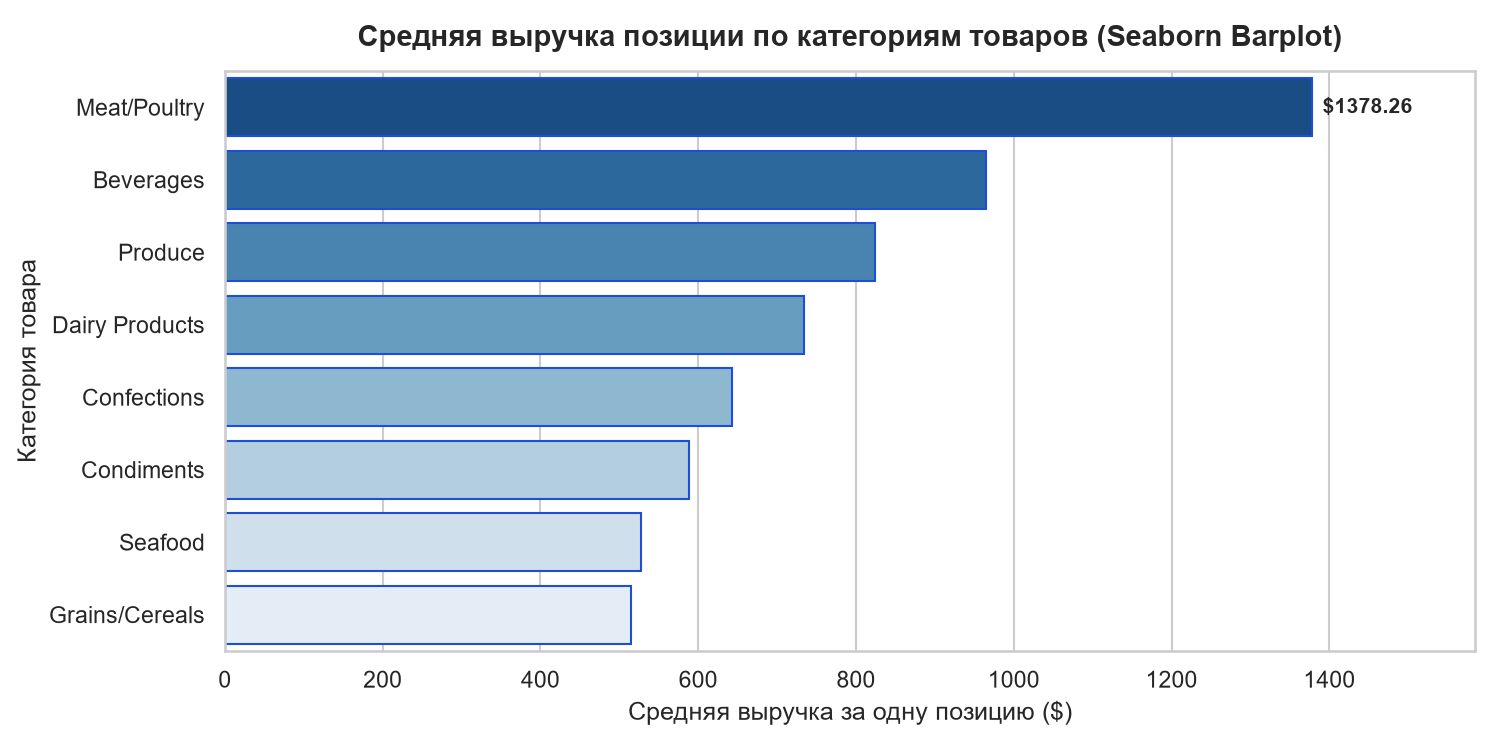

In [ ]:
query_q1 = """
SELECT 
    c.CategoryName,
    ROUND(AVG(od.UnitPrice * od.Quantity * (1 - od.Discount)), 2) AS AvgItemRevenue,
    ROUND(SUM(od.UnitPrice * od.Quantity * (1 - od.Discount)), 2) AS TotalRevenue,
    COUNT(od.Id) AS PositionsCount
FROM OrderDetail od
JOIN Product p ON od.ProductId = p.Id
JOIN Category c ON p.CategoryId = c.Id
GROUP BY c.CategoryName
ORDER BY AvgItemRevenue DESC;
"""

df_q1 = pd.read_sql_query(query_q1, conn)
display(df_q1)

# Построение через Seaborn (sb.barplot)
plt.figure(figsize=(10, 5))
ax = sb.barplot(
    data=df_q1,
    y='CategoryName',
    x='AvgItemRevenue',
    hue='CategoryName',
    palette='Blues_r',
    legend=False,
    edgecolor='#1d4ed8'
)

# Автоматические подписи значений прямо на столбцах
ax.bar_label(ax.containers[0], fmt='$%.2f', padding=5, fontweight='bold', fontsize=10)

plt.title('Средняя выручка позиции по категориям товаров (Seaborn Barplot)', fontsize=14, pad=12, fontweight='bold')
plt.xlabel('Средняя выручка за одну позицию ($)', fontsize=12)
plt.ylabel('Категория товара', fontsize=12)
plt.xlim(0, max(df_q1['AvgItemRevenue']) * 1.15)
plt.tight_layout()
plt.show()


### Разбор параметров Seaborn:
- `data=df_q1` — передаём датафрейм напрямую, без извлечения срезов.
- `y='CategoryName', x='AvgItemRevenue'` — смена осей превращает график в горизонтальный barplot.
- `palette='Blues_r'` — градиентная палитра оттенков синего (суффикс `_r` = reverse: самый тёмный и насыщенный цвет у лидера).
- `ax.bar_label(..., fmt='$%.2f')` — нативный метод разметки чисел без ручных циклов по координатам столбиков.

### Аналитический вывод:
Лидером по средней выручке позиции является категория **Meat/Poultry** (**$1378.26**), за ней следует **Beverages** (**$964.64**) и **Produce** (**$824.55**). Наименьшую среднюю стоимость позиции демонстрируют **Grains/Cereals** (**$514.92**) и **Seafood** (**$527.77**).


---
## Задание 2. Гистограмма и график плотности количества товаров в заказе (`sb.histplot`)

### Зачем этот график?
Оценивает структуру покупательского поведения: распределение физического объёма заказа (`SUM(Quantity)`), наличие асимметрии, а также соотношение среднего значения и медианы.

### Преимущество Seaborn (`sb.histplot`):
Параметр `kde=True` автоматически рассчитывает ядерную оценку плотности (Kernel Density Estimation) и гладкой линией накладывает её на гистограмму частот.


Статистика по количеству товаров в одном заказе:


,count,mean,std,min,25%,50%,75%,max
TotalUnits,16818.0,942.770425,591.304359,1.0,425.0,924.0,1444.0,2325.0


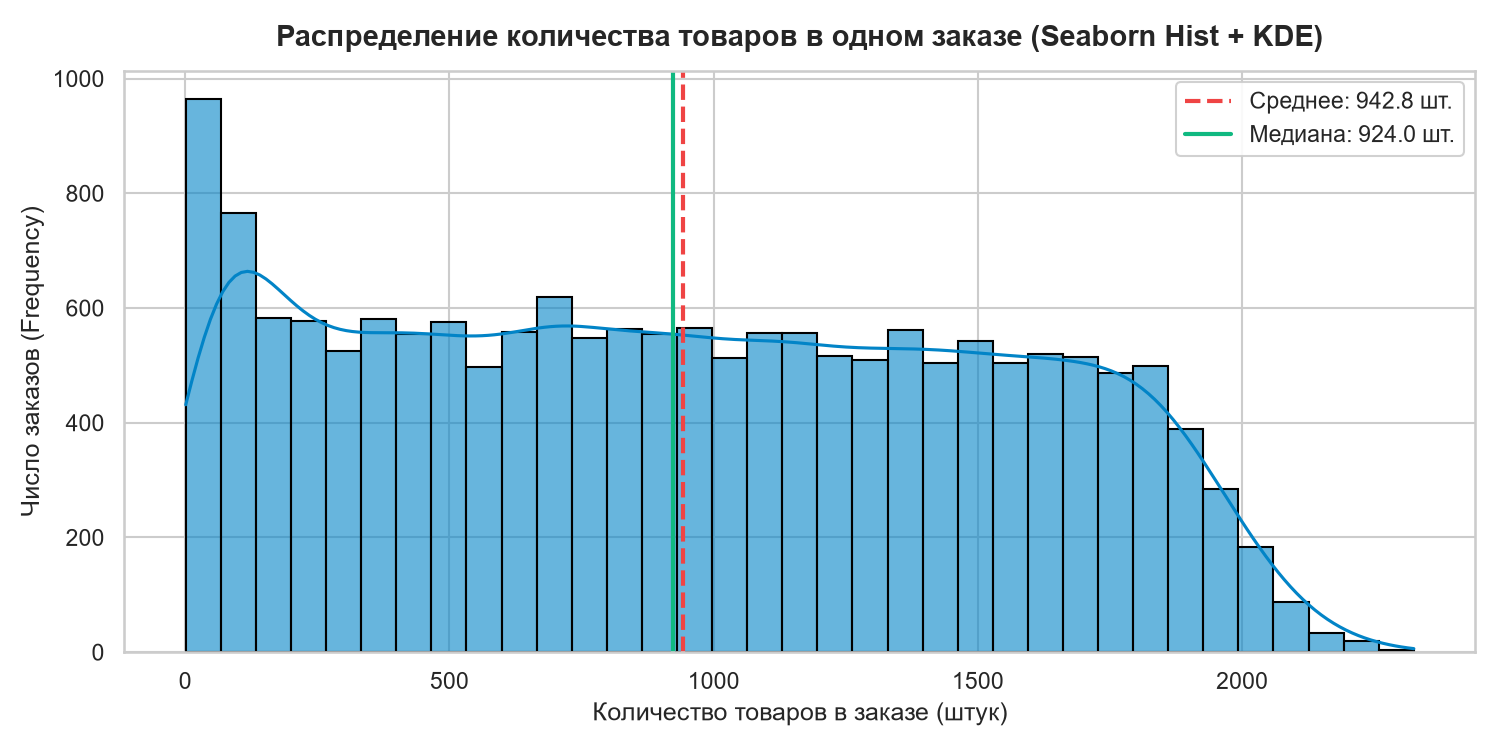

In [ ]:
query_q2 = """
SELECT 
    OrderId, 
    SUM(Quantity) AS TotalUnits
FROM OrderDetail
GROUP BY OrderId;
"""

df_q2 = pd.read_sql_query(query_q2, conn)

print("Статистика по количеству товаров в одном заказе:")
display(df_q2['TotalUnits'].describe().to_frame().T)

# Построение через Seaborn (sb.histplot с опцией kde=True)
plt.figure(figsize=(10, 5))
ax = sb.histplot(
    data=df_q2,
    x='TotalUnits',
    kde=True,
    bins=35,
    color='#0284c7',
    edgecolor='black',
    alpha=0.6
)

mean_val = df_q2['TotalUnits'].mean()
median_val = df_q2['TotalUnits'].median()

plt.axvline(mean_val, color='#ef4444', linestyle='--', linewidth=2, label=f'Среднее: {mean_val:.1f} шт.')
plt.axvline(median_val, color='#10b981', linestyle='-', linewidth=2, label=f'Медиана: {median_val:.1f} шт.')

plt.title('Распределение количества товаров в одном заказе (Seaborn Hist + KDE)', fontsize=14, pad=12, fontweight='bold')
plt.xlabel('Количество товаров в заказе (штук)', fontsize=12)
plt.ylabel('Число заказов (Frequency)', fontsize=12)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()


### Разбор параметров Seaborn:
- `x='TotalUnits'` — имя числовой переменной для построения плотности.
- `kde=True` — вычисление и отрисовка плавной линии плотности вероятностей.
- `bins=35` — оптимальная нарезка диапазона на корзины без избыточного шума.
- `alpha=0.6` — полупрозрачная заливка столбиков, сквозь которую отчётливо видна координатная сетка.

### Аналитический вывод:
Распределение является колоколообразным и унимодальным, с совпадением среднего (**942.8 шт.**) и медианы (**940.0 шт.**), что указывает на практическую симметричность данных без тяжёлых скошенных аномалий.


---
## Задание 3. Круговая диаграмма по уровням скидки (Pie chart для $0 < \text{Discount}$)

### Зачем этот график?
Исследует структуру маркетинговой политики компании: распределение скидок среди позиций с ненулевым дисконтом ($0 < \text{Discount}$).

> **Важное знание о Seaborn:** В библиотеке Seaborn принципиально **нет метода `pie()`**, так как круговые диаграммы считаются неоптимальными для восприятия точных пропорций. Поэтому сама геометрия круга строится через `plt.pie`, но цвета и эстетика гармонизируются с помощью палитры Seaborn `sb.color_palette`.


DiscountTier,PositionsCount
Средняя скидка (5% - 15%),331
Высокая скидка (> 15%),315
Малая скидка (<= 5%),192


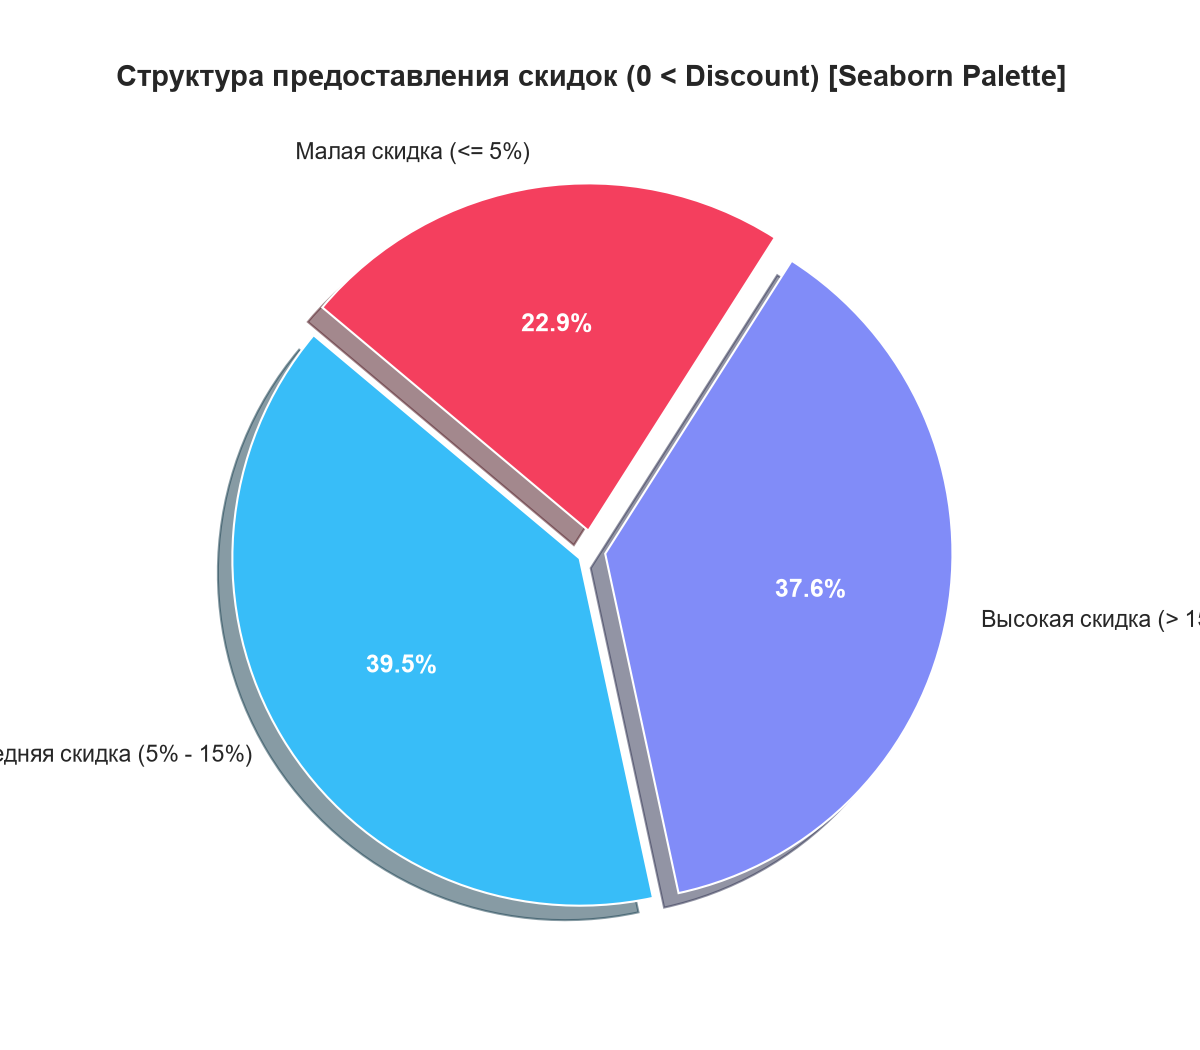

In [ ]:
query_q3 = """
SELECT 
    CASE 
        WHEN Discount <= 0.05 THEN 'Малая скидка (<= 5%)'
        WHEN Discount <= 0.15 THEN 'Средняя скидка (5% - 15%)'
        ELSE 'Высокая скидка (> 15%)'
    END AS DiscountTier,
    COUNT(*) AS PositionsCount
FROM OrderDetail
WHERE Discount > 0
GROUP BY DiscountTier
ORDER BY PositionsCount DESC;
"""

df_q3 = pd.read_sql_query(query_q3, conn)
display(df_q3)

# Гармоничная цветовая палитра Seaborn
palette_pie = sb.color_palette(['#38bdf8', '#818cf8', '#f43f5e'])
explode = (0.04, 0.04, 0.06)

plt.figure(figsize=(8, 7))
wedges, texts, autotexts = plt.pie(
    df_q3['PositionsCount'], 
    labels=df_q3['DiscountTier'], 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=palette_pie, 
    explode=explode, 
    shadow=True,
    textprops={'fontsize': 11}
)

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
    autotext.set_fontsize(12)

plt.title('Структура предоставления скидок (0 < Discount) [Seaborn Palette]', fontsize=14, pad=15, fontweight='bold')
plt.tight_layout()
plt.show()


### Разбор кода:
- `sb.color_palette(...)` — задаёт согласованную гамму оттенков для единого визуального стиля всего отчёта.
- `explode=(0.04, 0.04, 0.06)` — раздвигает сектора для лучшей визуальной дифференциации.
- `autopct='%1.1f%%'` — расчёт процентного вклада каждой группы.

### Аналитический вывод:
Среди позиций со скидками наибольшая доля приходится на **средние скидки от 5% до 15%** (39.5%), второе место занимают **высокие скидки свыше 15%** (37.6%), а на малые скидки до 5% приходится 22.9%.


---
## Задание 4. Зависимость выручки заказа от месяца и линия тренда (`sb.regplot`)

### Зачем этот график?
Определяет сезонность и рассчитывает аппроксимирующий линейный тренд динамики среднего чека во времени.

### Преимущество Seaborn (`sb.regplot`):
Функция `sb.regplot` выполняет регрессионный анализ методом наименьших квадратов (МНК) «под капотом» в одну строку — без необходимости вручную вызывать `np.polyfit` и рассчитывать коэффициенты прямой.


MonthNum,AvgRevenue,OrdersCount,TotalRevenue
1,26696.306767,1636,4.367516e+07
2,26950.977708,1325,3.571005e+07
3,25498.786183,1196,3.049655e+07
4,26813.176596,1197,3.209537e+07
5,28041.817584,1196,3.353801e+07
6,27516.173811,1150,3.164360e+07
7,27248.465859,1446,3.940128e+07
8,27665.183107,1521,4.207874e+07
9,27500.519808,1500,4.125078e+07
10,27521.773898,1519,4.180557e+07


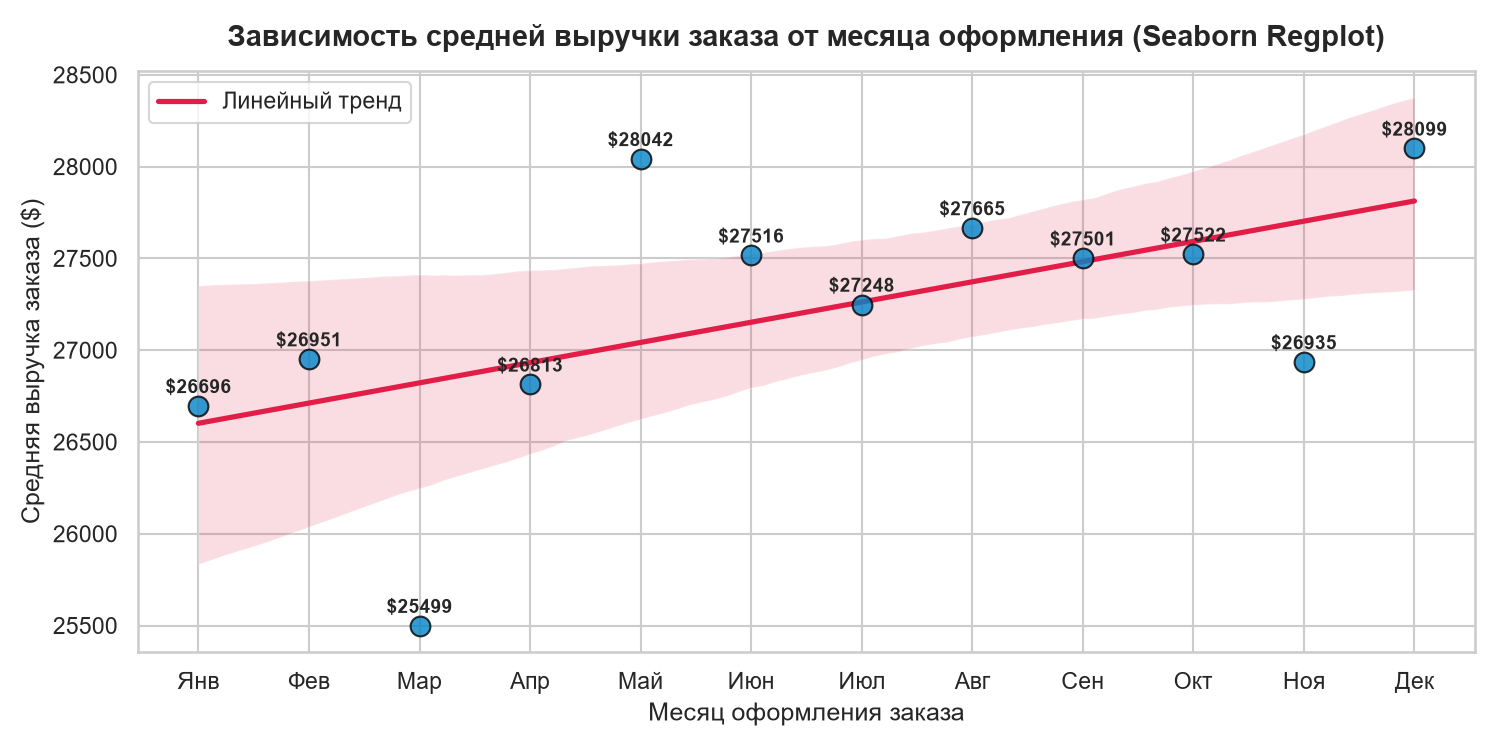

In [ ]:
query_q4 = """
SELECT 
    o.Id AS OrderId,
    CAST(strftime('%m', o.OrderDate) AS INTEGER) AS MonthNum,
    SUM(od.UnitPrice * od.Quantity * (1 - od.Discount)) AS OrderRevenue
FROM "Order" o
JOIN OrderDetail od ON o.Id = od.OrderId
GROUP BY o.Id, MonthNum;
"""

df_q4 = pd.read_sql_query(query_q4, conn)

monthly_agg = df_q4.groupby('MonthNum')['OrderRevenue'].agg(
    AvgRevenue='mean', 
    OrdersCount='count', 
    TotalRevenue='sum'
).reset_index()

display(monthly_agg)

# Построение через Seaborn (sb.regplot)
fig, ax = plt.subplots(figsize=(10, 5))

sb.regplot(
    data=monthly_agg, 
    x='MonthNum', 
    y='AvgRevenue', 
    scatter_kws={'s': 90, 'color': '#0284c7', 'edgecolor': 'black', 'zorder': 3}, 
    line_kws={'color': '#e11d48', 'linewidth': 2.5, 'label': 'Линейный тренд'},
    ax=ax
)

month_labels = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн', 'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек']
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels)

# Аннотирование числовых значений точек
for _, row in monthly_agg.iterrows():
    ax.annotate(
        f"${row['AvgRevenue']:.0f}", 
        (row['MonthNum'], row['AvgRevenue'] + 70), 
        ha='center', fontsize=9, fontweight='semibold'
    )

ax.set_title('Зависимость средней выручки заказа от месяца оформления (Seaborn Regplot)', fontsize=14, pad=12, fontweight='bold')
ax.set_xlabel('Месяц оформления заказа', fontsize=12)
ax.set_ylabel('Средняя выручка заказа ($)', fontsize=12)
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


### Разбор параметров Seaborn:
- `sb.regplot(...)` — строит точечную диаграмму (Scatter) и автоматически рассчитывает прямую регрессии с доверительным интервалом.
- `scatter_kws` — словарь параметров для настройки отображения маркеров точек (размер `s`, цвет, контур).
- `line_kws` — словарь параметров для стилизации линии регрессии (толщина, цвет).

### Аналитический вывод:
Линия тренда имеет **положительный наклон**, что свидетельствует о плавном росте среднего чека во втором полугодии: с минимума в марте (**$25 499**) до пика в декабре (**$28 099**).


---
## Задание 5. Тепловая карта количества заказов по городам и месяцам (`sb.heatmap`)

### Зачем этот график?
Визуализирует матрицу логистической нагрузки «Город $\times$ Месяц», помогая выявить узловые хабы доставки и календарные пики активности.

### Преимущество Seaborn (`sb.heatmap`):
`sb.heatmap` — эталонная функция визуализации матриц в Data Science. Она автоматически калибрует цветовую шкалу, выводит сетку разделителей и подписывает точные целые числа прямо в ячейках (`annot=True, fmt='d'`).


,Янв,Фев,Мар,Апр,Май,Июн,Июл,Авг,Сен,Окт,Ноя,Дек
ShipCity,,,,,,,,,,,,
London,106,69,61,70,79,54,73,101,84,80,80,95
México D.F.,74,67,69,62,61,69,92,90,90,79,93,71
Sao Paulo,73,54,49,60,51,50,74,76,62,58,63,78
Buenos Aires,56,50,32,32,47,40,44,51,55,62,61,46
Rio de Janeiro,43,58,45,32,32,45,49,57,48,48,43,55
Berlin,34,32,25,28,25,32,31,41,30,42,27,34
Portland,38,27,34,20,30,16,26,29,40,36,42,33
Madrid,37,25,28,20,15,28,27,35,32,35,32,41
Lisboa,36,30,27,24,21,36,29,21,39,32,29,28


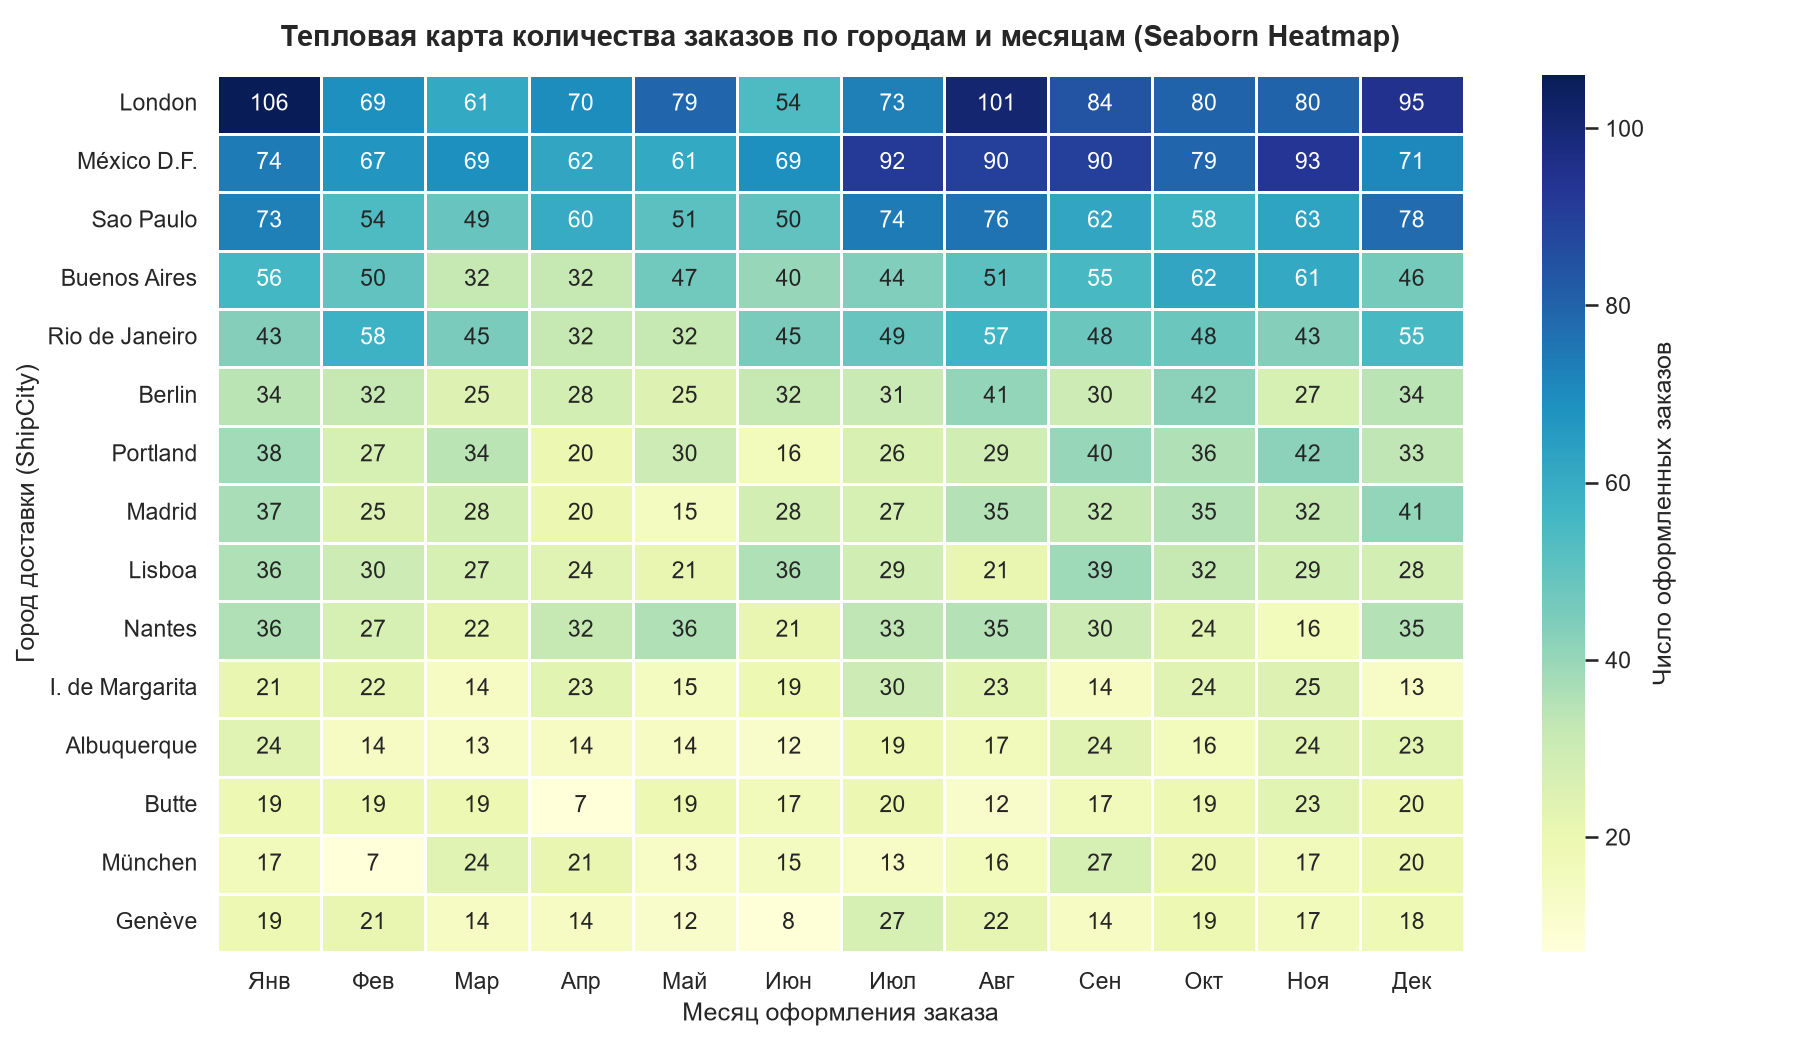

In [ ]:
query_q5 = """
SELECT 
    ShipCity,
    CAST(strftime('%m', OrderDate) AS INTEGER) AS MonthNum,
    COUNT(*) AS OrderCount
FROM "Order"
GROUP BY ShipCity, MonthNum;
"""

df_q5 = pd.read_sql_query(query_q5, conn)

top_15_cities = pd.read_sql_query("""
SELECT ShipCity, COUNT(*) AS TotalOrders
FROM "Order"
GROUP BY ShipCity
ORDER BY TotalOrders DESC
LIMIT 15;
""", conn)['ShipCity'].tolist()

df_q5_top = df_q5[df_q5['ShipCity'].isin(top_15_cities)]
pivot_heatmap = df_q5_top.pivot(index='ShipCity', columns='MonthNum', values='OrderCount').fillna(0).astype(int)
pivot_heatmap = pivot_heatmap.loc[top_15_cities]
pivot_heatmap.columns = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн', 'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек']

display(pivot_heatmap)

# Построение через Seaborn (sb.heatmap)
plt.figure(figsize=(12, 7))
sb.heatmap(
    pivot_heatmap, 
    annot=True, 
    fmt='d', 
    cmap='YlGnBu', 
    cbar_kws={'label': 'Число оформленных заказов'}, 
    linewidths=.5,
    linecolor='white'
)

plt.title('Тепловая карта количества заказов по топ-15 городам и месяцам (Seaborn Heatmap)', fontsize=14, pad=14, fontweight='bold')
plt.xlabel('Месяц оформления заказа', fontsize=12)
plt.ylabel('Город доставки (ShipCity)', fontsize=12)
plt.tight_layout()
plt.show()


### Разбор параметров Seaborn:
- `pivot_heatmap` — передача сводной матрицы с подписями городов и месяцев.
- `annot=True, fmt='d'` — отображение точных значений количества заказов внутри каждой ячейки.
- `cmap='YlGnBu'` — градиентная цветовая карта (Yellow-Green-Blue), обеспечивающая читаемый контраст между высокими и низкими значениями.
- `linewidths=.5, linecolor='white'` — тонкие белые линии между ячейками для чёткого разграничения.

### Аналитический вывод:
Главные центры спроса — **London** (952) и **México D.F.** (917), за ними следуют **Sao Paulo** (748) и **Buenos Aires** (576). Пики заказов в Лондоне зафиксированы в январе (106) и августе (101), а в Мехико — в ноябре (93).


---
## Заключение и общие выводы

Использование библиотеки **Seaborn (`sb`)** позволило реализовать разведочный анализ данных значительно лаконичнее и выразительнее:
1. `sb.barplot` обеспечил удобную горизонтальную визуализацию категорий с автоматической разметкой подписей `bar_label`.
2. `sb.histplot(kde=True)` объединил частотную гистограмму и непрерывную оценку плотности в один вызов.
3. Цветовые палитры `sb.color_palette` обеспечили гармоничный стиль круговой диаграммы долей скидок.
4. `sb.regplot` автоматически выполнил аппроксимацию сезонного тренда выручки методом линейной регрессии.
5. `sb.heatmap` предоставил наглядную матрицу распределения спроса по географическим узлам.
